In [11]:
import os
from pathlib import Path
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI

load_dotenv(Path.cwd() / ".env", override=False)

API_KEYS = {
    f"GEMINI_API{i}": os.getenv(f"GEMINI_API{i}")
    for i in range(1, 6)
}

missing = [
    name for name, key in API_KEYS.items()
    if not key or not key.strip()
]

if missing:
    raise ValueError(f"ไม่พบ API Key: {missing}")

MODEL_NAME = "gemini-3.5-flash-lite"

agents = {
    f"ai{i}": ChatGoogleGenerativeAI(
        model=MODEL_NAME,
        google_api_key=API_KEYS[f"GEMINI_API{i}"],
        temperature=0,
        max_retries=2,
    )
    for i in range(1, 6)
}

print(f"เตรียม Gemini agents แล้ว {len(agents)} ตัว")
print(f"Model: {MODEL_NAME}")

เตรียม Gemini agents แล้ว 5 ตัว
Model: gemini-3.5-flash-lite


In [12]:
from typing import TypedDict


class GoldState(TypedDict, total=False):
    question: str
    news: list[dict]

    ai1_analysis: str
    ai2_analysis: str
    ai3_analysis: str
    ai4_analysis: str

    final_answer: str

In [13]:
def response_to_text(response):
    """รองรับทั้ง string และ content แบบ list ของ LangChain."""
    content = response.content

    if isinstance(content, str):
        return content

    if isinstance(content, list):
        parts = []
        for block in content:
            if isinstance(block, dict) and block.get("type") == "text":
                parts.append(block["text"])
            elif isinstance(block, str):
                parts.append(block)
        return "\n".join(parts)

    return str(content)


def format_news(news):
    return "\n\n".join(
        f"ID: {item['id']}\n"
        f"Title: {item['title']}\n"
        f"Content: {item['content']}\n"
        f"Source: {item['source']}\n"
        f"Mock price change: {item['gold_price_change_pct']}%"
        for item in news
    )


def run_agent(agent_id, role, task, state):
    prompt = f"""
คุณเป็น {role} ในระบบวิจัยข่าวทองคำ

คำถาม: {state['question']}

ข้อมูลต่อไปนี้เป็น MOCK DATA ทั้งหมด
การเปลี่ยนแปลงราคาเป็นตัวเลขสมมติ ไม่ใช่ข้อมูลตลาดจริง

{format_news(state['news'])}

งานของคุณ:
{task}

ข้อกำหนด:
- ใช้เฉพาะข้อมูลที่ให้มาและความรู้ทั่วไปที่ระบุว่าเป็นกลไกที่เป็นไปได้
- แยกข้อเท็จจริงจากข้อมูลจำลองออกจากสมมติฐาน
- ห้ามกล่าวว่าข่าวเป็นสาเหตุของการเปลี่ยนแปลงราคาโดยไม่มีหลักฐาน
- ระบุข้อจำกัดและสิ่งที่ยังสรุปไม่ได้
- แสดงเหตุผลสรุปที่ตรวจสอบได้ ไม่ต้องเปิดเผย hidden chain-of-thought
- ตอบเป็นภาษาไทยอย่างมีโครงสร้าง
"""

    response = agents[agent_id].invoke(prompt)
    answer = response_to_text(response)

    print(f"\n{'=' * 20} {agent_id.upper()} | {role} {'=' * 20}")
    print(answer)
    print(f"{'=' * 60}\n")

    return answer


def news_agent(state):
    return {
        "ai1_analysis": run_agent(
            "ai1",
            "News Analyst",
            "สรุปเนื้อหาและหลักฐานที่ปรากฏในข่าวแต่ละรายการ",
            state,
        )
    }


def macro_agent(state):
    return {
        "ai2_analysis": run_agent(
            "ai2",
            "Macro Analyst",
            "อธิบายกลไกที่เป็นไปได้จากเงินเฟ้อ Fed ดอกเบี้ย "
            "ดอลลาร์ และ Bond Yield พร้อมระบุข้อมูลที่ยังขาด",
            state,
        )
    }


def market_agent(state):
    return {
        "ai3_analysis": run_agent(
            "ai3",
            "Market Analyst",
            "เปรียบเทียบตัวเลขราคาจำลองกับเนื้อหาข่าว "
            "ระบุรูปแบบที่สอดคล้องหรือไม่สอดคล้อง "
            "โดยไม่อนุมานเหตุและผลจากตัวเลขเพียงอย่างเดียว",
            state,
        )
    }


def risk_agent(state):
    return {
        "ai4_analysis": run_agent(
            "ai4",
            "Risk Analyst",
            "ตรวจสอบข้อโต้แย้ง ความกำกวม ความเสี่ยงในการสรุปเกินข้อมูล "
            "และหลักฐานที่ต้องมีก่อนยืนยันผลกระทบ",
            state,
        )
    }


def lead_researcher(state):
    prompt_state = {
        "question": state["question"],
        "news_analyst": state["ai1_analysis"],
        "macro_analyst": state["ai2_analysis"],
        "market_analyst": state["ai3_analysis"],
        "risk_analyst": state["ai4_analysis"],
    }

    prompt = f"""
คุณเป็น Lead Researcher ของระบบวิจัยข่าวทองคำ

คำถาม:
{prompt_state['question']}

ผลจาก News Analyst:
{prompt_state['news_analyst']}

ผลจาก Macro Analyst:
{prompt_state['macro_analyst']}

ผลจาก Market Analyst:
{prompt_state['market_analyst']}

ผลจาก Risk Analyst:
{prompt_state['risk_analyst']}

จงสังเคราะห์ผลโดย:
1. ระบุข้อสรุปที่ Agents เห็นตรงกัน
2. ระบุข้อขัดแย้งหรือข้อสรุปที่ยังไม่มีหลักฐานรองรับ
3. แยกข้อมูลจำลอง กลไกที่เป็นไปได้ และสิ่งที่ยังพิสูจน์ไม่ได้
4. สรุปว่าต้องใช้ข้อมูลใดเพิ่มเติมเพื่อทดสอบสมมติฐาน

ห้ามแต่งข้อมูลหรือแหล่งอ้างอิง
ห้ามกล่าวว่าความสัมพันธ์เป็นเหตุและผลโดยไม่มีหลักฐาน
ตอบเป็นภาษาไทย
"""

    response = agents["ai5"].invoke(prompt)
    answer = response_to_text(response)

    print(f"\n{'=' * 20} AI5 | LEAD RESEARCHER {'=' * 20}")
    print(answer)
    print(f"{'=' * 60}\n")

    return {"final_answer": answer}

In [14]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(GoldState)

builder.add_node("news_agent", news_agent)
builder.add_node("macro_agent", macro_agent)
builder.add_node("market_agent", market_agent)
builder.add_node("risk_agent", risk_agent)
builder.add_node("lead_researcher", lead_researcher)

# เริ่มพร้อมกัน 4 Agents
builder.add_edge(START, "news_agent")
builder.add_edge(START, "macro_agent")
builder.add_edge(START, "market_agent")
builder.add_edge(START, "risk_agent")

# รอให้ทั้ง 4 Agents เสร็จก่อน
builder.add_edge(
    [
        "news_agent",
        "macro_agent",
        "market_agent",
        "risk_agent",
    ],
    "lead_researcher",
)

builder.add_edge("lead_researcher", END)

multiagent_graph = builder.compile()

print("Multi-Agent Graph compiled successfully")

Multi-Agent Graph compiled successfully


In [15]:
mock_news = [
    {
        "id": "N001",
        "title": "US inflation rises above expectations",
        "content": (
            "US inflation data came in above market expectations. "
            "Investors reassessed the outlook for interest rates."
        ),
        "source": "Mock Financial News",
        "gold_price_change_pct": -0.8,
    },
    {
        "id": "N002",
        "title": "Federal Reserve signals possible rate cuts",
        "content": (
            "Policymakers indicated that interest-rate cuts "
            "could be considered if inflation continues to ease."
        ),
        "source": "Mock Central Bank News",
        "gold_price_change_pct": 1.2,
    },
    {
        "id": "N003",
        "title": "Gold demand rises during market uncertainty",
        "content": (
            "Investors increased demand for safe-haven assets "
            "amid heightened financial uncertainty."
        ),
        "source": "Mock Market News",
        "gold_price_change_pct": 0.5,
    },
]

mock_news

[{'id': 'N001',
  'title': 'US inflation rises above expectations',
  'content': 'US inflation data came in above market expectations. Investors reassessed the outlook for interest rates.',
  'source': 'Mock Financial News',
  'gold_price_change_pct': -0.8},
 {'id': 'N002',
  'title': 'Federal Reserve signals possible rate cuts',
  'content': 'Policymakers indicated that interest-rate cuts could be considered if inflation continues to ease.',
  'source': 'Mock Central Bank News',
  'gold_price_change_pct': 1.2},
 {'id': 'N003',
  'title': 'Gold demand rises during market uncertainty',
  'content': 'Investors increased demand for safe-haven assets amid heightened financial uncertainty.',
  'source': 'Mock Market News',
  'gold_price_change_pct': 0.5}]

In [16]:
result = multiagent_graph.invoke({
    "question": (
        "ข่าวจำลองเหล่านี้มีหลักฐานสนับสนุนกลไก "
        "ที่อาจส่งผลต่อราคาทองคำอย่างไร?"
    ),
    "news": mock_news,
})

print("\n\n######## FINAL RESEARCH REPORT ########\n")
print(result["final_answer"])

d:\Project_Github\gold assisstant\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\Project_Github\gold assisstant\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\Project_Github\gold assisstant\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\Project_Github\gold assisstant\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling pa


==================== AI1 | News Analyst ====================
ในฐานะนักวิเคราะห์ข่าวทองคำ ขอสรุปการวิเคราะห์ข้อมูลข่าวจำลอง (Mock Data) ตามกรอบข้อกำหนด ดังนี้ครับ

---

### 1. สรุปเนื้อหาและหลักฐานจากข้อมูลจำลอง

*   **ข่าว N001 (US inflation rises above expectations)**
    *   **เนื้อหา:** ตัวเลขเงินเฟ้อสหรัฐฯ ออกมาสูงกว่าที่ตลาดคาดการณ์ ทำให้นักลงทุนต้องประเมินแนวโน้มอัตราดอกเบี้ยใหม่
    *   **ข้อมูลจำลองราคา:** ราคาเปลี่ยนแปลง -0.8%
*   **ข่าว N002 (Federal Reserve signals possible rate cuts)**
    *   **เนื้อหา:** ผู้กำหนดนโยบายส่งสัญญาณว่าอาจมีการพิจารณาปรับลดอัตราดอกเบี้ย หากเงินเฟ้อยังคงชะลอตัวลง
    *   **ข้อมูลจำลองราคา:** ราคาเปลี่ยนแปลง +1.2%
*   **ข่าว N003 (Gold demand rises during market uncertainty)**
    *   **เนื้อหา:** นักลงทุนมีความต้องการสินทรัพย์ปลอดภัย (Safe-haven) เพิ่มขึ้นท่ามกลางความไม่แน่นอนทางการเงินที่สูงขึ้น
    *   **ข้อมูลจำลองราคา:** ราคาเปลี่ยนแปลง +0.5%

---

### 2. การแยกข้อเท็จจริงจากข้อมูลจำลองออกจากสมมติฐาน

*   **ข้อเท็จจริงจากข้อมูลจำลอง (Facts)

d:\Project_Github\gold assisstant\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(



==================== AI5 | LEAD RESEARCHER ====================
ในฐานะ Lead Researcher ของระบบวิจัยข่าวทองคำ ขอสรุปและสังเคราะห์ผลการวิเคราะห์จากทีมผู้เชี่ยวชาญ (News Analyst, Macro Analyst, Market Analyst และ Risk Analyst) ตามกรอบข้อกำหนด ดังนี้ครับ

---

### 1. ข้อสรุปที่ Agents เห็นตรงกัน (Consensus Findings)
*   **ความสอดคล้องเชิงทฤษฎี (Theoretical Alignment):** ทุกฝ่ายเห็นตรงกันว่า ทิศทางของการเปลี่ยนแปลงราคาในข้อมูลจำลอง (Mock Data) มีความสอดคล้องกับกลไกทางเศรษฐศาสตร์มหภาคทั่วไป ได้แก่:
    *   **N001 (เงินเฟ้อสูงกว่าคาด):** สอดคล้องกับทิศทางราคา -0.8% (เงินเฟ้อสูงหนุนดอกเบี้ยขาขึ้น กดดันทองคำ)
    *   **N002 (สัญญาณลดดอกเบี้ย):** สอดคล้องกับทิศทางราคา +1.2% (ดอกเบี้ยลดลง ลดต้นทุนค่าเสียโอกาส หนุนทองคำ)
    *   **N003 (ความไม่แน่นอนสูงขึ้น):** สอดคล้องกับทิศทางราคา +0.5% (ความต้องการสินทรัพย์ปลอดภัยหนุนทองคำ)
*   **ข้อจำกัดด้านความเป็นเหตุเป็นผล (Causality Limitation):** ทุกฝ่ายเห็นพ้องต้องกันว่า ข้อมูลจำลองนี้**ไม่สามารถยืนยันความสัมพันธ์เชิงสาเหตุ (Causality)** ได้ เนื่องจากเป

In [17]:
for key in [
    "ai1_analysis",
    "ai2_analysis",
    "ai3_analysis",
    "ai4_analysis",
    "final_answer",
]:
    print(f"\n--- {key} ---\n")
    print(result[key])


--- ai1_analysis ---

ในฐานะนักวิเคราะห์ข่าวทองคำ ขอสรุปการวิเคราะห์ข้อมูลข่าวจำลอง (Mock Data) ตามกรอบข้อกำหนด ดังนี้ครับ

---

### 1. สรุปเนื้อหาและหลักฐานจากข้อมูลจำลอง

*   **ข่าว N001 (US inflation rises above expectations)**
    *   **เนื้อหา:** ตัวเลขเงินเฟ้อสหรัฐฯ ออกมาสูงกว่าที่ตลาดคาดการณ์ ทำให้นักลงทุนต้องประเมินแนวโน้มอัตราดอกเบี้ยใหม่
    *   **ข้อมูลจำลองราคา:** ราคาเปลี่ยนแปลง -0.8%
*   **ข่าว N002 (Federal Reserve signals possible rate cuts)**
    *   **เนื้อหา:** ผู้กำหนดนโยบายส่งสัญญาณว่าอาจมีการพิจารณาปรับลดอัตราดอกเบี้ย หากเงินเฟ้อยังคงชะลอตัวลง
    *   **ข้อมูลจำลองราคา:** ราคาเปลี่ยนแปลง +1.2%
*   **ข่าว N003 (Gold demand rises during market uncertainty)**
    *   **เนื้อหา:** นักลงทุนมีความต้องการสินทรัพย์ปลอดภัย (Safe-haven) เพิ่มขึ้นท่ามกลางความไม่แน่นอนทางการเงินที่สูงขึ้น
    *   **ข้อมูลจำลองราคา:** ราคาเปลี่ยนแปลง +0.5%

---

### 2. การแยกข้อเท็จจริงจากข้อมูลจำลองออกจากสมมติฐาน

*   **ข้อเท็จจริงจากข้อมูลจำลอง (Facts):** 
    *   มีการรายงานตัวเลขเงินเฟ้อส

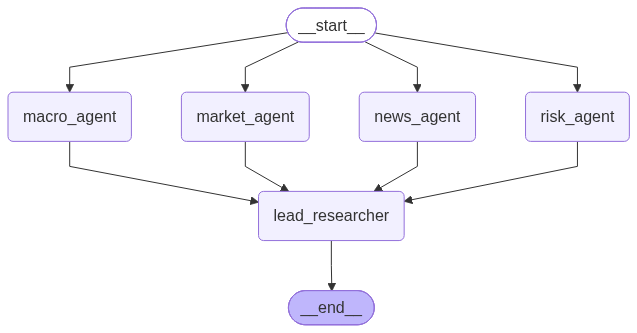

In [18]:
from IPython.display import Image, display

display(
    Image(
        multiagent_graph.get_graph().draw_mermaid_png()
    )
)

# function call

In [19]:
import pandas as pd
import numpy as np

market_data = pd.DataFrame([
    {"date":"2026-10-01","gold_usd":3850,"usdthb":32.10,"dxy":98.4,"us10y":4.12,"cpi_yoy":2.9},
    {"date":"2026-10-02","gold_usd":3868,"usdthb":32.05,"dxy":98.1,"us10y":4.10,"cpi_yoy":2.9},
    {"date":"2026-10-03","gold_usd":3842,"usdthb":32.20,"dxy":98.6,"us10y":4.16,"cpi_yoy":2.9},
    {"date":"2026-10-04","gold_usd":3880,"usdthb":32.15,"dxy":97.9,"us10y":4.08,"cpi_yoy":2.9},
    {"date":"2026-10-05","gold_usd":3905,"usdthb":32.00,"dxy":97.5,"us10y":4.02,"cpi_yoy":2.9},
    {"date":"2026-10-06","gold_usd":3890,"usdthb":32.08,"dxy":97.8,"us10y":4.05,"cpi_yoy":2.9},
    {"date":"2026-10-07","gold_usd":3920,"usdthb":31.95,"dxy":97.2,"us10y":3.98,"cpi_yoy":2.9},
    {"date":"2026-10-08","gold_usd":3910,"usdthb":32.02,"dxy":97.4,"us10y":4.00,"cpi_yoy":2.9},
    {"date":"2026-10-09","gold_usd":3945,"usdthb":31.90,"dxy":96.9,"us10y":3.94,"cpi_yoy":2.9},
    {"date":"2026-10-10","gold_usd":3960,"usdthb":31.85,"dxy":96.7,"us10y":3.91,"cpi_yoy":2.9},
])

market_data["date"] = pd.to_datetime(market_data["date"])

mock_news = [
    {
        "id": "N001",
        "date": "2026-10-03",
        "title": "Mock: US inflation remains elevated",
        "content": "The simulated CPI reading is 2.9% YoY. Markets reassess the rate outlook.",
        "topic": "inflation"
    },
    {
        "id": "N002",
        "date": "2026-10-05",
        "title": "Mock: US dollar weakens",
        "content": "The simulated DXY falls as market participants anticipate easier monetary policy.",
        "topic": "dollar"
    },
    {
        "id": "N003",
        "date": "2026-10-07",
        "title": "Mock: US Treasury yields decline",
        "content": "The simulated US 10Y yield declines to 3.98%.",
        "topic": "bond_yield"
    },
    {
        "id": "N004",
        "date": "2026-10-09",
        "title": "Mock: Gold reaches a new period high",
        "content": "The simulated gold price reaches USD 3,945 per troy ounce.",
        "topic": "gold"
    },
]

display(market_data)
display(pd.DataFrame(mock_news))

,date,gold_usd,usdthb,dxy,us10y,cpi_yoy
0,2026-10-01,3850,32.10,98.4,4.12,2.9
1,2026-10-02,3868,32.05,98.1,4.10,2.9
2,2026-10-03,3842,32.20,98.6,4.16,2.9
3,2026-10-04,3880,32.15,97.9,4.08,2.9
4,2026-10-05,3905,32.00,97.5,4.02,2.9
5,2026-10-06,3890,32.08,97.8,4.05,2.9
6,2026-10-07,3920,31.95,97.2,3.98,2.9
7,2026-10-08,3910,32.02,97.4,4.00,2.9
8,2026-10-09,3945,31.90,96.9,3.94,2.9
9,2026-10-10,3960,31.85,96.7,3.91,2.9


,id,date,title,content,topic
0,N001,2026-10-03,Mock: US inflation remains elevated,The simulated CPI reading is 2.9% YoY. Markets...,inflation
1,N002,2026-10-05,Mock: US dollar weakens,The simulated DXY falls as market participants...,dollar
2,N003,2026-10-07,Mock: US Treasury yields decline,The simulated US 10Y yield declines to 3.98%.,bond_yield
3,N004,2026-10-09,Mock: Gold reaches a new period high,"The simulated gold price reaches USD 3,945 per...",gold


In [20]:
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, ToolMessage
import json

In [21]:
@tool
def search_mock_news(query: str) -> str:
    """ค้นข่าวจำลองด้วย keyword เช่น gold, dollar, inflation, bond_yield."""
    q = query.lower()

    matches = [
        n for n in mock_news
        if q in json.dumps(n, ensure_ascii=False).lower()
    ]

    return json.dumps(matches, ensure_ascii=False, indent=2)

In [22]:
@tool
def calculate_macro_changes() -> str:
    """คำนวณการเปลี่ยนแปลงระหว่างวันแรกและวันสุดท้ายของ DXY, US10Y, USDTHB และทองคำ"""

    first = market_data.iloc[0]
    last = market_data.iloc[-1]

    result = {}

    for col in ["gold_usd", "usdthb", "dxy", "us10y"]:
        result[col] = {
            "start": float(first[col]),
            "end": float(last[col]),
            "absolute_change": round(float(last[col] - first[col]), 4),
            "percent_change": round(
                float((last[col] / first[col] - 1) * 100), 4
            )
        }

    return json.dumps(result, ensure_ascii=False, indent=2)

In [23]:
@tool
def calculate_quant_statistics() -> str:
    """คำนวณผลตอบแทนทองคำ ค่า correlation และสถิติจากข้อมูลจำลอง"""

    df = market_data.copy()

    df["gold_return_pct"] = df["gold_usd"].pct_change() * 100
    df["dxy_return_pct"] = df["dxy"].pct_change() * 100
    df["usdthb_return_pct"] = df["usdthb"].pct_change() * 100

    valid = df.dropna(subset=["gold_return_pct", "dxy_return_pct"])

    result = {
        "observations": int(len(df)),
        "daily_return_observations": int(len(valid)),
        "gold_total_return_pct": round(
            float((df["gold_usd"].iloc[-1] /
                   df["gold_usd"].iloc[0] - 1) * 100), 4
        ),
        "gold_daily_return_mean_pct": round(
            float(valid["gold_return_pct"].mean()), 4
        ),
        "gold_daily_return_std_pct": round(
            float(valid["gold_return_pct"].std()), 4
        ),
        "gold_dxy_daily_return_correlation": round(
            float(valid["gold_return_pct"].corr(
                valid["dxy_return_pct"]
            )), 4
        ),
        "gold_usdthb_daily_return_correlation": round(
            float(valid["gold_return_pct"].corr(
                valid["usdthb_return_pct"]
            )), 4
        )
    }

    return json.dumps(result, ensure_ascii=False, indent=2)

In [24]:
@tool
def audit_market_data() -> str:
    """ตรวจสอบ missing values, duplicate dates และ daily price moves ที่เกิน 2%"""

    df = market_data.copy()
    daily_return = df["gold_usd"].pct_change() * 100

    result = {
        "row_count": int(len(df)),
        "missing_values": {
            k: int(v) for k, v in df.isna().sum().items()
        },
        "duplicate_dates": int(df["date"].duplicated().sum()),
        "gold_daily_moves_over_2pct": [
            {
                "date": df.iloc[i]["date"].strftime("%Y-%m-%d"),
                "return_pct": round(float(daily_return.iloc[i]), 4)
            }
            for i in range(1, len(df))
            if abs(daily_return.iloc[i]) > 2
        ],
        "warning": (
            "ข้อมูลมีเพียง 10 วัน และเป็น Mock Data "
            "จึงไม่เพียงพอสำหรับยืนยันความสัมพันธ์เชิงสาเหตุ"
        )
    }

    return json.dumps(result, ensure_ascii=False, indent=2)

In [25]:
@tool
def verify_final_evidence() -> str:
    """ดึงตัวเลขอ้างอิงจากข้อมูลต้นทางเพื่อให้ Lead Researcher ตรวจสอบรายงาน"""

    first = market_data.iloc[0]
    last = market_data.iloc[-1]

    result = {
        "source": "mock_market_data",
        "rows": int(len(market_data)),
        "date_start": first["date"].strftime("%Y-%m-%d"),
        "date_end": last["date"].strftime("%Y-%m-%d"),
        "gold_start_usd": float(first["gold_usd"]),
        "gold_end_usd": float(last["gold_usd"]),
        "gold_return_pct": round(
            float((last["gold_usd"] / first["gold_usd"] - 1) * 100), 4
        ),
        "dxy_start": float(first["dxy"]),
        "dxy_end": float(last["dxy"]),
        "us10y_start_pct": float(first["us10y"]),
        "us10y_end_pct": float(last["us10y"]),
        "evidence_limit": (
            "ตัวเลขเหล่านี้เป็นข้อมูลจำลอง ไม่ใช่หลักฐานของตลาดจริง "
            "และไม่ยืนยันว่า macro variables เป็นสาเหตุของราคาทอง"
        )
    }

    return json.dumps(result, ensure_ascii=False, indent=2)

In [26]:
from langchain_core.messages import AIMessage

agent_tools = {
    "ai1": [search_mock_news],
    "ai2": [calculate_macro_changes],
    "ai3": [calculate_quant_statistics],
    "ai4": [audit_market_data],
    "ai5": [verify_final_evidence],
}

tool_maps = {
    agent_id: {t.name: t for t in tools}
    for agent_id, tools in agent_tools.items()
}

tool_enabled_models = {
    agent_id: agents[agent_id].bind_tools(tools)
    for agent_id, tools in agent_tools.items()
}

def run_tool_agent(agent_id, role, task, context=""):
    model = tool_enabled_models[agent_id]
    messages = [
        HumanMessage(content=f"""
คุณคือ {role} ในระบบวิจัยตลาดทองคำ

งานของคุณ:
{task}

บริบทจาก Agent ก่อนหน้า:
{context}

กติกา:
- ต้องเรียก Tool ที่คุณได้รับอย่างน้อย 1 ครั้งก่อนสรุป
- ใช้ผลจาก Tool เป็นแหล่งอ้างอิงตัวเลข
- แยกข้อเท็จจริงออกจากสมมติฐาน
- ห้ามอ้างว่า Mock Data เป็นข้อมูลตลาดจริง
- ตอบภาษาไทยและอธิบายผลอย่างกระชับ
""")
    ]

    tool_log = []
    max_rounds = 5

    for _ in range(max_rounds):
        response = model.invoke(messages)
        messages.append(response)

        calls = getattr(response, "tool_calls", [])

        if not calls:
            answer = response_to_text(response)
            return {
                "analysis": answer,
                "tool_calls": tool_log
            }

        for call in calls:
            name = call["name"]
            args = call["args"]
            tool = tool_maps[agent_id].get(name)

            if tool is None:
                result = f"Error: Tool {name} is not available to {agent_id}."
            else:
                try:
                    result = tool.invoke(args)
                except Exception as exc:
                    result = f"Tool error: {type(exc).__name__}: {exc}"

            if not isinstance(result, str):
                result = json.dumps(result, ensure_ascii=False, default=str)

            tool_log.append({
                "tool": name,
                "arguments": args,
                "result": result
            })

            messages.append(
                ToolMessage(
                    content=result,
                    tool_call_id=call["id"]
                )
            )

    raise RuntimeError(
        f"{agent_id} ใช้ Tool เกิน {max_rounds} รอบโดยยังไม่ตอบจบ"
    )

In [27]:
result1 = run_tool_agent(
    "ai1",
    "News Analyst",
    "ค้นข่าวที่เกี่ยวกับ dollar แล้วรายงานข่าวที่พบ"
)
print(result1["analysis"])
print("Tool calls:", [x["tool"] for x in result1["tool_calls"]])

d:\Project_Github\gold assisstant\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\Project_Github\gold assisstant\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


ในฐานะ News Analyst ในระบบวิจัยตลาดทองคำ ขอรายงานข่าวที่เกี่ยวข้องกับค่าเงินดอลลาร์จากระบบฐานข้อมูลจำลอง (Mock Data) ดังนี้ครับ

### รายงานข่าวค่าเงินดอลลาร์ (Mock Data)
* **หัวข้อข่าว:** US dollar weakens (วันที่ 5 ตุลาคม 2026)
* **เนื้อหาข่าว:** ดัชนีดอลลาร์สหรัฐฯ (Simulated DXY) ปรับตัวลดลง เนื่องจากผู้เล่นในตลาดคาดการณ์ว่าธนาคารกลางสหรัฐฯ จะดำเนินนโยบายทางการเงินที่ผ่อนคลายมากขึ้น (easier monetary policy)

---

### การวิเคราะห์แยกแยะ (ตามกติกา)

1. **ข้อเท็จจริง (Facts จากระบบจำลอง):**
   * ดัชนีค่าเงินดอลลาร์สหรัฐฯ (DXY) ปรับตัวอ่อนค่าลงในวันที่ 5 ตุลาคม 2026
   * ตลาดคาดการณ์ทิศทางนโยบายการเงินที่ผ่อนคลายลง

2. **สมมติฐาน (Hypothesis / การวิเคราะห์ผลกระทบต่อทองคำ):**
   * *หมายเหตุ: ข้อมูลนี้เป็นข้อมูลจำลอง (Mock Data) ห้ามนำไปอ้างอิงเป็นข้อมูลตลาดจริง* 
   * หากอ้างอิงตามหลักเศรษฐศาสตร์ทั่วไป การที่ค่าเงินดอลลาร์อ่อนค่าลงจากความคาดหวังเรื่องนโยบายการเงินที่ผ่อนคลาย มักจะเป็นปัจจัยหนุน (Bullish) ให้ราคาทองคำปรับตัวสูงขึ้น เนื่องจากต้นทุนในการถือครองทองคำสำหรับผู้ถือสกุลเงินอื่นลด

In [28]:
result2 = run_tool_agent(
    "ai2",
    "Macro Analyst",
    "คำนวณการเปลี่ยนแปลงของตัวแปรเศรษฐกิจทั้งหมดและตีความอย่างระมัดระวัง"
)
print(result2["analysis"])
print("Tool calls:", [x["tool"] for x in result2["tool_calls"]])

d:\Project_Github\gold assisstant\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\Project_Github\gold assisstant\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


ในฐานะ Macro Analyst ของระบบวิจัยตลาดทองคำ ขอรายงานการวิเคราะห์การเปลี่ยนแปลงของตัวแปรมหภาคสำคัญ ดังนี้ครับ

### 1. ข้อเท็จจริงจากการคำนวณ (Data & Facts)
จากการประมวลผลข้อมูลการเปลี่ยนแปลงระหว่างวันแรกและวันสุดท้าย ตัวแปรสำคัญมีความเคลื่อนไหว 4 ด้าน ดังนี้ครับ:
*   **ดัชนีค่าเงินดอลลาร์ (DXY):** ปรับตัวลดลงจาก 98.4 สู่ระดับ 96.7 คิดเป็นการเปลี่ยนแปลง **-1.70 จุด (-1.73%)**
*   **อัตราผลตอบแทนพันธบัตรรัฐบาลสหรัฐฯ 10 ปี (US10Y):** ปรับตัวลดลงจาก 4.12% สู่ระดับ 3.91% คิดเป็นการเปลี่ยนแปลง **-0.21% (-5.10%)**
*   **ราคาทองคำ (Gold USD):** ปรับตัวเพิ่มขึ้นจาก $3,850 สู่ระดับ $3,960 ต่อออนซ์ คิดเป็นการเปลี่ยนแปลง **+$110 (+2.86%)**
*   **อัตราแลกเปลี่ยน (USDTHB):** ปรับตัวแข็งค่าขึ้น (เงินบาทแข็งขึ้นเทียบดอลลาร์) จาก 32.10 สู่ระดับ 31.85 คิดเป็นการเปลี่ยนแปลง **-0.25 บาท (-0.78%)**

---

### 2. การตีความและวิเคราะห์เชิงมหภาค (Interpretation & Assumptions)
*   **ความสัมพันธ์ของตัวแปร (Correlation):** ทิศทางของตลาดสอดคล้องกับทฤษฎีเศรษฐศาสตร์มหภาคแบบดั้งเดิม โดยการอ่อนค่าของดัชนี DXY และการปรับ

In [29]:
result3 = run_tool_agent(
    "ai3",
    "Quant Analyst",
    "วิเคราะห์ผลตอบแทนและ correlation พร้อมระบุข้อจำกัดของ sample size"
)
print(result3["analysis"])
print("Tool calls:", [x["tool"] for x in result3["tool_calls"]])

d:\Project_Github\gold assisstant\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\Project_Github\gold assisstant\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


ในฐานะ Quant Analyst ขอสรุปผลการวิเคราะห์เชิงปริมาณจากชุดข้อมูลจำลอง (Mock Data) ดังนี้ครับ:

### 1. ผลการวิเคราะห์ทางสถิติและผลตอบแทน (จาก Tool)
* **ผลตอบแทนรวมของทองคำ (Gold Total Return):** $+2.85\%$ (จากข้อมูลชุดจำลองจำนวน 10 วัน / 9 ช่วงผลตอบแทนรายวัน)
* **ค่าเฉลี่ยผลตอบแทนรายวัน (Mean Daily Return):** $+0.32\%$ ต่อวัน
* **ความผันผวนรายวัน (Daily Return Standard Deviation):** $0.60\%$
* **ความสัมพันธ์ระหว่างราคาทองคำกับค่าเงินดอลลาร์ (Gold vs DXY Correlation):** $-0.9931$ (มีความสัมพันธ์ในทิศทางตรงกันข้ามกันสูงมาก)
* **ความสัมพันธ์ระหว่างราคาทองคำกับอัตราแลกเปลี่ยน THB (Gold vs USDTHB Correlation):** $-0.9196$

---

### 2. ข้อจำกัดของขนาดกลุ่มตัวอย่าง (Sample Size Limitations)
* **ขนาดตัวอย่างน้อยเกินไป (Small Sample Size):** ข้อมูลมีเพียง $N = 10$ วัน (9 จุดข้อมูลผลตอบแทน) ซึ่ง **ต่ำเกินไป** ในทางสถิติที่จะนำไปใช้ยืนยันนัยสำคัญทางสถิติ (Statistical Significance) หรือสร้างโมเดลทำนายราคา
* **ความเสี่ยงเรื่อง Overfitting:** เนื่องจากจำนวนตัวอย่างน้อย ค่า Correlation ที่สูงมาก (เช่น 

In [30]:
result4 = run_tool_agent(
    "ai4",
    "Risk Analyst",
    "ตรวจสอบคุณภาพข้อมูลและความเสี่ยงจากการสรุปผลเกินหลักฐาน"
)
print(result4["analysis"])
print("Tool calls:", [x["tool"] for x in result4["tool_calls"]])

d:\Project_Github\gold assisstant\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\Project_Github\gold assisstant\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


ในฐานะ Risk Analyst ของระบบวิจัยตลาดทองคำ ขอรายงานผลการตรวจสอบคุณภาพข้อมูลและความเสี่ยงจากการสรุปผล ดังนี้ครับ:

### 1. ผลการตรวจสอบคุณภาพข้อมูล (จาก Tool `audit_market_data`)
* **จำนวนข้อมูล:** มีทั้งหมด 10 แถว (Row count: 10)
* **ความสมบูรณ์:** ไม่พบ Missing Values และไม่พบวันที่ซ้ำ (Duplicate dates)
* **ความผันผวนรายวัน:** ไม่พบการเปลี่ยนแปลงของราคาทองคำเกิน 2% (0 วัน)
* **ข้อจำกัดสำคัญ:** ชุดข้อมูลดังกล่าวมีขนาดเล็กเกินไป (เพียง 10 วัน) และ **เป็นข้อมูลจำลอง (Mock Data)** ไม่ใช่ข้อมูลตลาดจริง

---

### 2. การวิเคราะห์ความเสี่ยงจากการสรุปผลเกินหลักฐาน (Over-claiming Risk)
เนื่องจากข้อจำกัดของชุดข้อมูล การนำผลวิเคราะห์จากข้อมูลนี้ไปสรุปผลเชิงนโยบายหรือการลงทุนมีความเสี่ยงสูง ดังนี้:

* **ข้อเท็จจริง (Facts):** 
  * ชุดข้อมูลตัวอย่างมีความสมบูรณ์ในแง่ของโครงสร้าง (ไม่มีค่าว่างหรือข้อมูลซ้ำ) และไม่มีความผันผวนของราคาทองคำเกิน 2% ในช่วง 10 วันดังกล่าว
* **สมมติฐานที่ต้องระวัง (Hypotheses / Fallacies):** 
  * **ห้ามสรุปความสัมพันธ์เชิงสาเหตุ (Causality):** ไม่สามารถนำข้อมูล 10 วันนี้ไปสร

In [31]:
previous_results = "\n\n".join([
    "AI1 News Analysis:\n" + result1["analysis"],
    "AI2 Macro Analysis:\n" + result2["analysis"],
    "AI3 Quant Analysis:\n" + result3["analysis"],
    "AI4 Risk Analysis:\n" + result4["analysis"],
])

result5 = run_tool_agent(
    "ai5",
    "Lead Researcher",
    """
    ตรวจสอบหลักฐานจาก Agent ทั้งสี่ตัว
    เรียก Tool เพื่อตรวจตัวเลขอ้างอิงจากข้อมูลต้นทาง
    จากนั้นเขียนรายงานสุดท้าย โดยแบ่งเป็น:
    1. สิ่งที่ข้อมูลแสดง
    2. ความสัมพันธ์ที่พบ
    3. ข้อจำกัดและสิ่งที่ยังสรุปไม่ได้
    4. ข้อมูลเพิ่มเติมที่ต้องเก็บก่อนนำไปใช้จริง
    """,
    context=previous_results
)

print(result5["analysis"])
print("Tool calls:", [x["tool"] for x in result5["tool_calls"]])

d:\Project_Github\gold assisstant\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\Project_Github\gold assisstant\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


ในฐานะ Lead Researcher ของระบบวิจัยตลาดทองคำ ขอสรุปรายงานวิเคราะห์จากข้อมูลต้นทาง (Mock Data) ที่ผ่านการตรวจสอบความถูกต้องเรียบร้อยแล้ว ดังนี้ครับ:

---

### 1. สิ่งที่ข้อมูลแสดง (Facts & Evidence)
จากชุดข้อมูลจำลอง (Mock Data) จำนวน 10 วัน (ตั้งแต่วันที่ 1 ถึง 10 ตุลาคม 2026) ที่ตรวจสอบผ่านระบบ มีข้อเท็จจริงทางสถิติ ดังนี้:
* **ราคาทองคำ (Gold USD):** ปรับตัวเพิ่มขึ้นจาก $3,850 สู่ระดับ $3,960 ต่อออนซ์ คิดเป็นผลตอบแทนรวม $+2.86\%$ (หรือคำนวณแบบผลตอบแทนรวมได้ $+2.85\%$)
* **ดัชนีค่าเงินดอลลาร์ (DXY):** ปรับตัวลดลงจาก 98.4 สู่ระดับ 96.7 (ลดลง $-1.70$ จุด หรือ $-1.73\%$)
* **อัตราผลตอบแทนพันธบัตรรัฐบาลสหรัฐฯ 10 ปี (US10Y):** ลดลงจาก $4.12\%$ สู่ระดับ $3.91\%$ (ลดลง $-0.21\%$ หรือ $-5.10\%$)
* **อัตราแลกเปลี่ยน (USDTHB):** ปรับตัวลดลงจาก 32.10 สู่ระดับ 31.85 (เงินบาทแข็งค่าขึ้น $-0.78\%$)
* **ความสัมพันธ์ทางสถิติ:** ทองคำมีความสัมพันธ์ในทิศทางตรงกันข้ามกับ DXY ในระดับสูงมาก (Correlation $-0.9931$) และกับ USDTHB (Correlation $-0.9196$) โดยโครงสร้างข้อมูลมีความสมบูรณ์ ไม่มีค่าว่าง (Missing 

In [32]:
all_results = {
    "AI1 News Analyst": result1,
    "AI2 Macro Analyst": result2,
    "AI3 Quant Analyst": result3,
    "AI4 Risk Analyst": result4,
    "AI5 Lead Researcher": result5,
}

for agent_name, result in all_results.items():
    print(f"\n{'=' * 60}")
    print(agent_name)
    print("จำนวน Tool Calls:", len(result["tool_calls"]))

    for call in result["tool_calls"]:
        print("Tool:", call["tool"])
        print("Arguments:", call["arguments"])
        print("Returned data:", call["result"][:500])


AI1 News Analyst
จำนวน Tool Calls: 1
Tool: search_mock_news
Arguments: {'query': 'dollar'}
Returned data: [
  {
    "id": "N002",
    "date": "2026-10-05",
    "title": "Mock: US dollar weakens",
    "content": "The simulated DXY falls as market participants anticipate easier monetary policy.",
    "topic": "dollar"
  }
]

AI2 Macro Analyst
จำนวน Tool Calls: 1
Tool: calculate_macro_changes
Arguments: {}
Returned data: {
  "gold_usd": {
    "start": 3850.0,
    "end": 3960.0,
    "absolute_change": 110.0,
    "percent_change": 2.8571
  },
  "usdthb": {
    "start": 32.1,
    "end": 31.85,
    "absolute_change": -0.25,
    "percent_change": -0.7788
  },
  "dxy": {
    "start": 98.4,
    "end": 96.7,
    "absolute_change": -1.7,
    "percent_change": -1.7276
  },
  "us10y": {
    "start": 4.12,
    "end": 3.91,
    "absolute_change": -0.21,
    "percent_change": -5.0971
  }
}

AI3 Quant Analyst
จำนวน Tool Calls: 1
Tool: calculate_quant_statistics
Arguments: {}
Returned data: {
  "observa

## function call : HMM

In [9]:
import os
import json
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, ToolMessage
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

# ใช้โฟลเดอร์โปรเจกต์เป็นฐาน
PROJECT_DIR = Path(r"D:\Project_Github\gold assisstant")

MODEL_PATH = Path(r"D:\Project_Github\gold assisstant\model\gold_hmm_v1\model.joblib")
DATA_PATH = Path(r"D:\Project_Github\gold assisstant\dataset\datset a gold price\data\processed\thai_gold_features_v1.csv")

load_dotenv(PROJECT_DIR / ".env", override=False)

# ใช้ API Key แรกเพื่อทดสอบ Function Calling ก่อน
API_KEY = os.getenv("GEMINI_API1")
if not API_KEY:
    raise ValueError("ไม่พบ GEMINI_API1 ในไฟล์ .env")

MODEL_NAME = "gemini-3.5-flash-lite"

llm = ChatGoogleGenerativeAI(
    model=MODEL_NAME,
    google_api_key=API_KEY,
    temperature=0,
    max_retries=2,
)

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"ไม่พบ Model: {MODEL_PATH}")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"ไม่พบ Dataset: {DATA_PATH}\n"
        "แก้ DATA_PATH ให้ตรงกับตำแหน่ง CSV ในเครื่อง"
    )

model_bundle = joblib.load(MODEL_PATH)
gold_df = pd.read_csv(DATA_PATH)

hmm_model = model_bundle["model"]
scaler = model_bundle["scaler"]
FEATURE_COLS = model_bundle["feature_cols"]

print("Model:", model_bundle.get("model_name"))
print("Version:", model_bundle.get("model_version"))
print("Features:", FEATURE_COLS)
print("Rows:", len(gold_df))
print("HMM states:", hmm_model.n_components)

Model: GaussianHMM
Version: 1.0.0
Features: ['bar_buy_log_return', 'intraday_range_pct']
Rows: 6261
HMM states: 3


In [10]:
gold_df["timestamp_parsed"] = pd.to_datetime(
    gold_df["timestamp_parsed"], errors="coerce"
)
gold_df["date"] = pd.to_datetime(
    gold_df["date"], errors="coerce"
)

gold_df = (
    gold_df.sort_values("timestamp_parsed")
    .reset_index(drop=True)
)

# Feature 1: log return ของราคาทองคำแท่งซื้อ
gold_df["bar_buy_log_return"] = np.log(
    gold_df["bar_buy"] / gold_df["bar_buy"].shift(1)
)

# Feature 2: proxy จากช่วงราคาซื้อที่พบในแต่ละวัน
# ไม่ใช่ High-Low range หาก bar_buy ไม่ใช่ราคาสูงสุด/ต่ำสุด
daily_high = gold_df.groupby("date")["bar_buy"].transform("max")
daily_low = gold_df.groupby("date")["bar_buy"].transform("min")

gold_df["intraday_range_pct"] = (
    (daily_high - daily_low) / gold_df["bar_buy"] * 100
)

X_raw = gold_df[FEATURE_COLS].replace(
    [np.inf, -np.inf], np.nan
)

valid_mask = X_raw.notna().all(axis=1)

X_raw = X_raw.loc[valid_mask]
valid_df = gold_df.loc[valid_mask].copy()

if X_raw.empty:
    raise ValueError("ไม่มีแถวที่มี Features ครบถ้วน")

# ใช้ StandardScaler จาก Model Bundle
X_scaled = scaler.transform(X_raw)

if X_scaled.shape[1] != hmm_model.n_features:
    raise ValueError(
        f"Feature mismatch: got {X_scaled.shape[1]}, "
        f"model expects {hmm_model.n_features}"
    )

print("Valid observations:", len(X_scaled))
print("Feature columns:", FEATURE_COLS)
print("Scaled shape:", X_scaled.shape)
print("WARNING: intraday_range_pct currently uses a proxy.")

Valid observations: 6260
Feature columns: ['bar_buy_log_return', 'intraday_range_pct']
Scaled shape: (6260, 2)


d:\Project_Github\gold assisstant\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [11]:
@tool
def analyze_gold_hmm_regime(last_n_rows: int = 10) -> str:
    """
    วิเคราะห์ Statistical Regime ของตลาดทองคำด้วย GaussianHMM
    คืน State, posterior probabilities และสถิติของช่วงข้อมูลล่าสุด
    last_n_rows ต้องอยู่ระหว่าง 1 ถึง 100
    """
    if not 1 <= last_n_rows <= 100:
        return json.dumps(
            {"error": "last_n_rows ต้องอยู่ระหว่าง 1 ถึง 100"},
            ensure_ascii=False
        )

    states = hmm_model.predict(X_scaled)
    probs = hmm_model.predict_proba(X_scaled)

    n = min(last_n_rows, len(states))
    start = len(states) - n

    recent = []

    for i in range(start, len(states)):
        recent.append({
            "timestamp": str(
                valid_df.iloc[i]["timestamp_parsed"]
            ),
            "state": int(states[i]),
            "posterior": {
                f"state_{j}": round(float(p), 6)
                for j, p in enumerate(probs[i])
            }
        })

    result = {
        "model_name": model_bundle.get("model_name"),
        "model_version": model_bundle.get("model_version"),
        "feature_cols": FEATURE_COLS,
        "observations": len(X_scaled),
        "latest_timestamp": str(
            valid_df.iloc[-1]["timestamp_parsed"]
        ),
        "latest_state": int(states[-1]),
        "latest_posterior": {
            f"state_{j}": round(float(p), 6)
            for j, p in enumerate(probs[-1])
        },
        "recent_observations": recent,
        "warnings": [
            "intraday_range_pct currently uses an experimental proxy",
            "States are statistical regimes, not confirmed crisis labels",
            "This model is not a standalone trading signal",
            "predict_proba may use future observations through sequence smoothing"
        ]
    }

    return json.dumps(result, ensure_ascii=False, indent=2)

In [12]:
test_result = analyze_gold_hmm_regime.invoke(
    {"last_n_rows": 10}
)

print(test_result)

{
  "model_name": "GaussianHMM",
  "model_version": "1.0.0",
  "feature_cols": [
    "bar_buy_log_return",
    "intraday_range_pct"
  ],
  "observations": 6260,
  "latest_timestamp": "2026-10-13 12:09:00",
  "latest_state": 0,
  "latest_posterior": {
    "state_0": 0.999802,
    "state_1": 0.000159,
    "state_2": 3.9e-05
  },
  "recent_observations": [
    {
      "timestamp": "2026-10-04 09:02:00",
      "state": 0,
      "posterior": {
        "state_0": 0.999847,
        "state_1": 0.000136,
        "state_2": 1.7e-05
      }
    },
    {
      "timestamp": "2026-10-05 16:47:00",
      "state": 0,
      "posterior": {
        "state_0": 0.999832,
        "state_1": 0.000143,
        "state_2": 2.6e-05
      }
    },
    {
      "timestamp": "2026-10-06 15:57:00",
      "state": 0,
      "posterior": {
        "state_0": 0.999834,
        "state_1": 0.000143,
        "state_2": 2.2e-05
      }
    },
    {
      "timestamp": "2026-10-07 17:08:00",
      "state": 0,
      "posterior"

In [13]:
tools = [analyze_gold_hmm_regime]
tool_map = {t.name: t for t in tools}
llm_with_tools = llm.bind_tools(tools)

def content_to_text(content):
    if isinstance(content, str):
        return content

    if isinstance(content, list):
        parts = []
        for block in content:
            if isinstance(block, dict) and block.get("type") == "text":
                parts.append(block["text"])
            elif isinstance(block, str):
                parts.append(block)
        return "\n".join(parts)

    return str(content)


def run_hmm_agent(question: str, max_rounds: int = 5):
    messages = [
        HumanMessage(content=f"""
คุณคือ Quant Research Analyst ที่วิเคราะห์ตลาดทองคำไทย

คำถาม:
{question}

คุณมี Function Tool สำหรับเรียก GaussianHMM
ต้องใช้ Tool ก่อนสรุปผล
อ้างอิงตัวเลขจาก Tool เท่านั้น
ห้ามตั้งชื่อ State เป็น Bull, Bear หรือ Crisis โดยไม่มีหลักฐาน
แยกข้อเท็จจริงออกจากสมมติฐาน
ตอบเป็นภาษาไทย
""")
    ]

    tool_history = []

    for _ in range(max_rounds):
        response = llm_with_tools.invoke(messages)
        messages.append(response)

        calls = getattr(response, "tool_calls", [])

        if not calls:
            return {
                "answer": content_to_text(response.content),
                "tool_calls": tool_history
            }

        for call in calls:
            tool_name = call["name"]
            tool_args = call["args"]

            if tool_name not in tool_map:
                tool_result = json.dumps({
                    "error": f"Unknown tool: {tool_name}"
                })
            else:
                try:
                    tool_result = tool_map[tool_name].invoke(tool_args)
                except Exception as exc:
                    tool_result = json.dumps({
                        "error": type(exc).__name__,
                        "message": str(exc)
                    })

            tool_history.append({
                "name": tool_name,
                "arguments": tool_args,
                "result": tool_result
            })

            messages.append(
                ToolMessage(
                    content=tool_result,
                    tool_call_id=call["id"]
                )
            )

    raise RuntimeError(
        f"Gemini ยังไม่ตอบจบหลังจาก {max_rounds} รอบ"
    )

In [14]:
result = run_hmm_agent(
    """
    วิเคราะห์ Regime ล่าสุดจาก GaussianHMM
    รายงาน State ล่าสุด, Posterior Probability,
    การเปลี่ยน State ใน 10 แถวล่าสุด และข้อจำกัด
    ห้ามให้คำแนะนำซื้อขาย
    """
)

print("=== GEMINI ANSWER ===")
print(result["answer"])

print("\n=== FUNCTION CALL LOG ===")
for item in result["tool_calls"]:
    print("Tool:", item["name"])
    print("Arguments:", item["arguments"])
    print("Returned data:")
    print(item["result"][:1500])
    print("-" * 60)

d:\Project_Github\gold assisstant\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\Project_Github\gold assisstant\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


=== GEMINI ANSWER ===
ในฐานะ Quant Research Analyst ขอรายงานผลการวิเคราะห์ Statistical Regime ของตลาดทองคำด้วยโมเดล GaussianHMM (Version 1.0.0, ใช้ฟีเจอร์ `bar_buy_log_return` และ `intraday_range_pct` บนชุดข้อมูลจำนวน 6,260 สังเกตการณ์) โดยอ้างอิงตัวเลขจากระบบเครื่องมือดังนี้:

### 1. ผลการวิเคราะห์ Regime ล่าสุด
* **ข้อมูล ณ วันเวลา:** 2026-10-13 12:09:00
* **State ล่าสุด:** State 0
* **Posterior Probability ของ State ล่าสุด:** 
  * State 0: $0.999802$ (ประมาณ 99.98%)
  * State 1: $0.000159$ (ประมาณ 0.016%)
  * State 2: $0.000039$ (ประมาณ 0.0039%)

---

### 2. การเปลี่ยน State ใน 10 แถวล่าสุด
จากการติดตามข้อมูล 10 ช่วงเวลาล่าสุด (ระหว่างวันที่ 2026-10-04 ถึง 2026-10-13) ผลปรากฏดังนี้:
1. **2026-10-04 09:02:00** — State: 0 (Posterior State 0: 0.999847)
2. **2026-10-05 16:47:00** — State: 0 (Posterior State 0: 0.999832)
3. **2026-10-06 15:57:00** — State: 0 (Posterior State 0: 0.999834)
4. **2026-10-07 17:08:00** — State: 0 (Posterior State 0: 0.999824)
5. **2026-10-08 16:18:00** — Stat

In [15]:
states = hmm_model.predict(X_scaled)
probs = hmm_model.predict_proba(X_scaled)

regime_df = valid_df[["timestamp_parsed"]].copy()
regime_df["state"] = states

for j in range(hmm_model.n_components):
    regime_df[f"state_{j}_prob"] = probs[:, j]

display(regime_df.tail(20))

,timestamp_parsed,state,state_0_prob,state_1_prob,state_2_prob
6241,2026-09-24 16:48:00,0,0.999800,0.000158,0.000042
6242,2026-09-25 17:15:00,0,0.999833,0.000142,0.000025
6243,2026-09-26 09:05:00,0,0.999845,0.000137,0.000017
6244,2026-09-27 09:01:00,0,0.999808,0.000143,0.000048
6245,2026-09-28 16:52:00,0,0.800177,0.000446,0.199376
6246,2026-09-29 17:07:00,0,0.999791,0.000155,0.000054
6247,2026-09-30 16:26:00,0,0.999811,0.000150,0.000039
6248,2026-10-01 17:27:00,0,0.999841,0.000140,0.000019
6249,2026-10-02 17:16:00,0,0.999846,0.000137,0.000017
6250,2026-10-03 09:02:00,0,0.999797,0.000159,0.000044
